# Detection v6: a cluster channel against the v8 adversary

Detection v5 showed that v8's adaptive adversary (a pipeline of open rounds, interleaved edges, a
slow rate) removes v4's short-window, per-wallet evidence in the active markets. v6 adds a channel
for the property no execution can hide: a wash group's volume stays inside the group.

- **Communities**: Louvain on the counterparty graph (resolution 1; 2 as sensitivity).
- **Wallet score**: $s_i = (a_i - e_i)/\max(1 - e_i, a_i)$, where $a_i$ is the share of the wallet's
  volume inside its community and $e_i$ the same share under volume-proportional mixing.
- **Pair score**: $\min(s_i, s_j)$ inside a community, 0 across.
- **Fusion**: v4's rules (control tail probability, floor 0.5, max evidence, pooled control
  FPR 1%). `v6` = v4's seven channels + `cluster`.
- **Applicability**: the channel is used only where the control runs mix (mean control
  modularity < 0.3: the active backgrounds). In thin and thick, v6 is v4.

Labels: beneficial owner (primary), order label in parentheses or as a second column. This
notebook only reads results. Set `RUN_DETECTION = True` to rerun (about 16 minutes with 12 jobs).

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path


def _find_root(start):
    for p in [start, *start.parents]:
        if (p / "marketsim").is_dir() and (p / "capstone codes").is_dir():
            return p
    raise RuntimeError("repository root not found above " + str(start))


ROOT = _find_root(Path.cwd().resolve())
for p in (str(ROOT), str(ROOT / "capstone codes")):
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from washtrade.v8 import design as D
from washtrade.v8 import generate as G
from detection.v6 import experiment as X

DET6 = ROOT / "capstone codes" / "detection" / "v6"

## Configuration

In [2]:
# Folder holding ds_v8_<sweep>/. Set the WASH_V8_DATA environment variable, or edit this line.
DATA = Path(os.environ.get("WASH_V8_DATA") or (ROOT / "capstone codes" / "washtrade" / "v8" / "data"))
RUN_DETECTION = False                 # True = smoke test + detection on both sweeps (~16 min)
JOBS = 12                             # 15 ran out of memory on 16 GB in an earlier rescore
SWEEPS = list(D.SWEEPS)
missing = [sw for sw in SWEEPS if not (Path(G.dataset_root(sw, out_dir=str(DATA))) / "manifest.csv").exists()]
print("sweeps:", SWEEPS, "| missing datasets:", missing or "none")

sweeps: ['adversary', 'honest'] | missing datasets: none


## 1. Smoke test and detection (only if `RUN_DETECTION`)

In [3]:
if RUN_DETECTION:
    res = subprocess.run([sys.executable, str(DET6 / "run_smoke.py")], cwd=ROOT,
                         capture_output=True, text=True, encoding="utf-8")
    print(res.stdout.splitlines()[-1])
    if res.returncode != 0:
        raise RuntimeError("smoke test failed:\n" + res.stdout[-2000:])
    t0 = time.time()
    X.run_all(SWEEPS, jobs=JOBS, data=str(DATA))
    print(f"detection done in {(time.time() - t0) / 60:.0f} min")
else:
    print("RUN_DETECTION is False: reading existing results")

RUN_DETECTION is False: reading existing results


## 2. Load results

In [4]:
R = {sw: pd.read_csv(Path(X.out_dir(sw, str(DATA))) / "results.csv") for sw in SWEEPS}
TH = pd.read_csv(X.thresholds_path(str(DATA)))
APP = pd.read_csv(X.backgrounds_path(str(DATA)))
print({sw: f"{R[sw]['run_id'].nunique()} runs x {R[sw]['method'].nunique()} methods" for sw in SWEEPS})

BGA = ["active", "active_dense", "thin", "thick"]          # active first: the main baseline
EXEC = [("sequential", 1), ("interleaved", 1), ("sequential", 4), ("interleaved", 4),
        ("sequential", 8), ("interleaved", 8)]
EXEC_LABEL = {e: f"{e[0][:5]}, D={e[1]}" for e in EXEC}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6,
})
OWN = ["trade_tp", "trade_fp", "trade_pos", "trade_neg", "trade_tp_owner", "trade_fp_owner",
       "trade_pos_owner", "trade_neg_owner", "trade_fp_touch", "trade_neg_touch", "trade_fp_far",
       "trade_neg_far", "wallet_tp", "wallet_fp", "wallet_pos", "wallet_neg"]


def pooled(df, by):
    # Volume-pooled metrics under both labels (sum over runs, then divide), the FPR split, mean AP.
    g = df.groupby(by)
    s = g[OWN].sum()
    return pd.DataFrame({
        "recall (owner)": s.trade_tp_owner / s.trade_pos_owner,
        "recall (orders)": s.trade_tp / s.trade_pos,
        "precision (owner)": s.trade_tp_owner / (s.trade_tp_owner + s.trade_fp_owner),
        "precision (orders)": s.trade_tp / (s.trade_tp + s.trade_fp),
        "FPR (owner)": s.trade_fp_owner / s.trade_neg_owner,
        "FPR touch": s.trade_fp_touch / s.trade_neg_touch,
        "FPR far": s.trade_fp_far / s.trade_neg_far,
        "AP (owner)": g.trade_ap_owner.mean(),
        "wallet recall": s.wallet_tp / s.wallet_pos,
        "wallet FPR": s.wallet_fp / s.wallet_neg,
    })


def heat(ax, piv, vmin=0, vmax=1, cmap="Blues", fmt="{:.2f}"):
    ax.imshow(piv.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(piv.shape[1]), piv.columns, rotation=0)
    ax.set_yticks(range(piv.shape[0]), piv.index)
    for (i, j), v in np.ndenumerate(piv.values):
        if np.isfinite(v):
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9,
                    color="white" if (v - vmin) / (vmax - vmin) > 0.6 else "#0b0b0b")


aw = R["adversary"][R["adversary"].f_scenario == "wash"]
hn = R["honest"]

{'adversary': '20000 runs x 16 methods', 'honest': '8000 runs x 16 methods'}


## 3. Where the cluster channel applies, and its thresholds

Mean modularity of the resolution-1 partitions of the control runs. Above 0.3, honest trading alone
already forms strong communities, and the channel is off. The cluster thresholds sit just above the
floor 0.5 in the active backgrounds (`cluster_r2`: no control pair reaches the floor, so any score
at or above it is flagged; shown as -1).

In [5]:
display(APP.round(3))
display(TH[(TH.floor == 0.5) & TH.method.isin(["closure", "cluster", "cluster_r2", "v4", "v6", "v6_r2"])]
        .pivot(index="background", columns="method", values="theta_1").round(4))

,background,control_modularity,n_control_runs,cluster_enabled
0,active,0.149,200,True
1,active_dense,0.174,200,True
2,active_dense_mu4,0.189,200,True
3,active_mu4,0.163,200,True
4,thick,0.389,200,False
5,thick_mu4,0.470,200,False
6,thin,0.420,200,False
7,thin_mu4,0.469,200,False


method,closure,cluster,cluster_r2,v4,v6,v6_r2
background,,,,,,
active,0.9800,0.5118,-1.0000,0.9966,0.9966,0.9966
active_dense,0.9627,0.5033,-1.0000,0.9966,0.9966,0.9966
active_dense_mu4,1.0000,0.5005,0.5155,0.9947,0.9949,0.9947
active_mu4,1.0000,0.5014,-1.0000,0.9947,0.9948,0.9947
thick,0.8088,-1.0000,-1.0000,0.9969,0.9969,0.9969
thick_mu4,0.8867,-1.0000,-1.0000,0.9973,0.9973,0.9973
thin,0.8403,-1.0000,-1.0000,0.9958,0.9958,0.9958
thin_mu4,0.8450,-1.0000,-1.0000,0.9969,0.9969,0.9969


## 4. Recall by execution: v4 vs v6 (`adversary` sweep)

Owner label. Rows are the six executions at each wash rate; v4 is detection v5's result (same
detector, same thresholds).

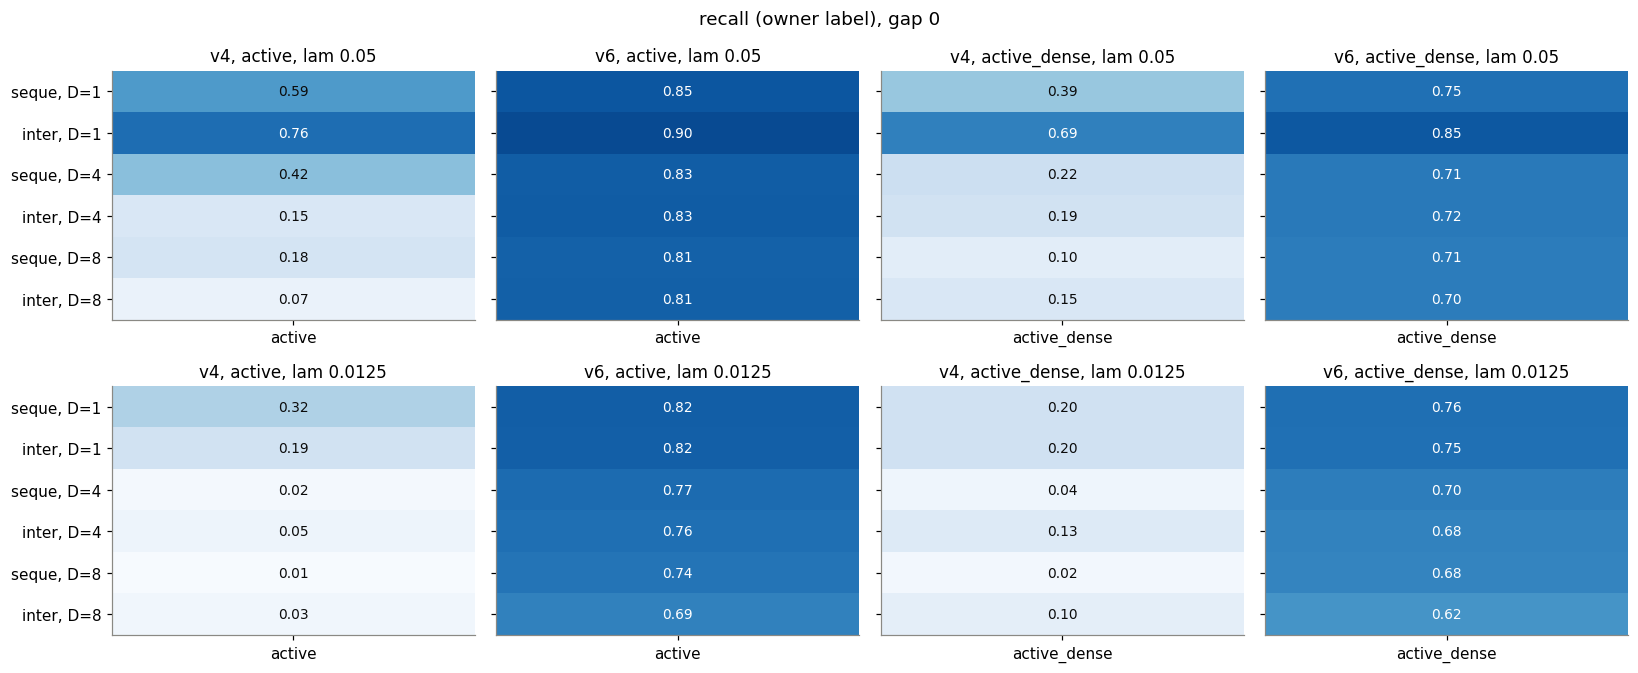

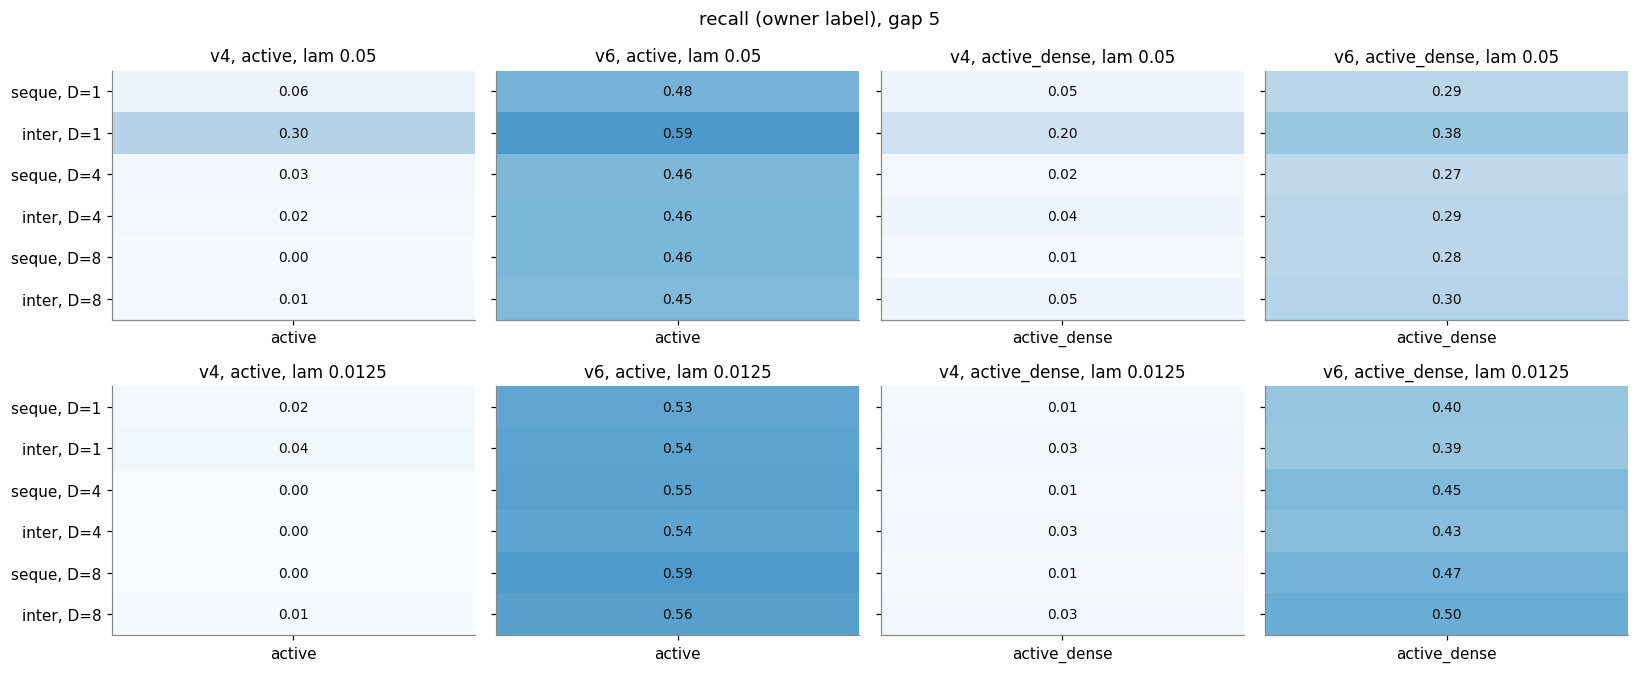

In [6]:
for gap in (0, 5):
    fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
    for i, lam in enumerate((0.05, 0.0125)):
        s = aw[(aw.f_gap == gap) & (aw.f_lam_wash == lam) & aw.method.isin(["v4", "v6"])]
        p = pooled(s, ["method", "f_edge_order", "f_pipeline", "background"])["recall (owner)"]
        for j, (m, b) in enumerate([("v4", "active"), ("v6", "active"), ("v4", "active_dense"), ("v6", "active_dense")]):
            piv = p.loc[m].unstack("background")[[b]].reindex(pd.MultiIndex.from_tuples(EXEC))
            piv.index = [EXEC_LABEL[e] for e in EXEC]
            heat(axes[i][j], piv)
            axes[i][j].set_title(f"{m}, {b}, lam {lam}")
            if j:
                axes[i][j].set_yticklabels([])
    fig.suptitle(f"recall (owner label), gap {gap}")
    fig.tight_layout()

## 5. Precision, FPR and ranking, pooled over every execution

FPR in wash runs is split into honest volume that **touches** a wash wallet and volume **far**
from the group. Thin and thick: the cluster channel is off, so `v6` = `v4`.

In [7]:
M = ["closure", "v4", "cluster", "v6", "cluster_r2", "v6_r2"]
for gap in (0, 5):
    print(f"gap {gap}")
    t = pooled(aw[(aw.f_gap == gap) & aw.method.isin(M)], ["method", "background"])
    display(t.reindex(pd.MultiIndex.from_product([M, BGA])).round(3))

gap 0


recall (owner)  recall (orders)  precision (owner)  \
closure    active                 0.086            0.098              0.979   
           active_dense           0.138            0.149              0.876   
           thin                   0.511            0.637              0.987   
           thick                  0.569            0.668              0.942   
v4         active                 0.300            0.345              0.980   
           active_dense           0.249            0.275              0.922   
           thin                   0.654            0.817              0.993   
           thick                  0.677            0.799              0.969   
cluster    active                 0.804            0.842              0.949   
           active_dense           0.696            0.716              0.951   
           thin                   0.000            0.000                NaN   
           thick                  0.000            0.000                NaN   
v6         active                 0.822            0.860              0.931   
           active_dense           0.731            0.752              0.926   
           thin                   0.654            0.817              0.993   
           thick                  0.677            0.799              0.969   
cluster_r2 active                 0.769            0.813              0.997   
           active_dense           0.647            0.669              0.997   
           thin                   0.000            0.000                NaN   
           thick                  0.000            0.000                NaN   
v6_r2      active                 0.789            0.833              0.989   
           active_dense           0.688            0.712              0.968   
           thin                   0.654            0.817              0.993   
           thick                  0.677            0.799              0.969   

                         precision (orders)  FPR (owner)  FPR touch  FPR far  \
closure    active                     0.962        0.000      0.001    0.000   
           active_dense               0.843        0.001      0.003    0.001   
           thin                       0.958        0.020      0.024    0.005   
           thick                      0.919        0.028      0.041    0.012   
v4         active                     0.970        0.001      0.002    0.001   
           active_dense               0.906        0.001      0.003    0.001   
           thin                       0.965        0.014      0.017    0.004   
           thick                      0.948        0.018      0.026    0.007   
cluster    active                     0.854        0.007      0.019    0.001   
           active_dense               0.871        0.002      0.011    0.000   
           thin                         NaN        0.000      0.000    0.000   
           thick                        NaN        0.000      0.000    0.000   
v6         active                     0.838        0.009      0.025    0.003   
           active_dense               0.849        0.004      0.014    0.001   
           thin                       0.965        0.014      0.017    0.004   
           thick                      0.948        0.018      0.026    0.007   
cluster_r2 active                     0.905        0.000      0.001    0.000   
           active_dense               0.918        0.000      0.001    0.000   
           thin                         NaN        0.000      0.000    0.000   
           thick                        NaN        0.000      0.000    0.000   
v6_r2      active                     0.898        0.001      0.003    0.001   
           active_dense               0.891        0.001      0.004    0.001   
           thin                       0.965        0.014      0.017    0.004   
           thick                      0.948        0.018      0.026    0.007   

                         AP (owner)  wallet reca

gap 5


recall (owner)  recall (orders)  precision (owner)  \
closure    active                 0.013            0.017              0.878   
           active_dense           0.050            0.061              0.473   
           thin                   0.416            0.565              0.981   
           thick                  0.433            0.567              0.880   
v4         active                 0.054            0.077              0.922   
           active_dense           0.050            0.068              0.574   
           thin                   0.513            0.702              0.988   
           thick                  0.468            0.618              0.933   
cluster    active                 0.470            0.464              0.883   
           active_dense           0.307            0.254              0.768   
           thin                   0.000            0.000                NaN   
           thick                  0.000            0.000                NaN   
v6         active                 0.501            0.505              0.859   
           active_dense           0.342            0.301              0.717   
           thin                   0.513            0.702              0.988   
           thick                  0.468            0.618              0.933   
cluster_r2 active                 0.386            0.375              0.990   
           active_dense           0.227            0.175              0.975   
           thin                   0.000            0.000                NaN   
           thick                  0.000            0.000                NaN   
v6_r2      active                 0.410            0.408              0.980   
           active_dense           0.263            0.223              0.860   
           thin                   0.513            0.702              0.988   
           thick                  0.468            0.618              0.933   

                         precision (orders)  FPR (owner)  FPR touch  FPR far  \
closure    active                     0.784        0.000      0.000    0.000   
           active_dense               0.372        0.001      0.003    0.001   
           thin                       0.935        0.021      0.024    0.005   
           thick                      0.832        0.035      0.047    0.017   
v4         active                     0.891        0.000      0.001    0.000   
           active_dense               0.506        0.001      0.002    0.001   
           thin                       0.947        0.016      0.018    0.006   
           thick                      0.891        0.020      0.028    0.008   
cluster    active                     0.593        0.005      0.014    0.001   
           active_dense               0.407        0.002      0.010    0.000   
           thin                         NaN        0.000      0.000    0.000   
           thick                        NaN        0.000      0.000    0.000   
v6         active                     0.589        0.007      0.018    0.001   
           active_dense               0.404        0.003      0.012    0.001   
           thin                       0.947        0.016      0.018    0.006   
           thick                      0.891        0.020      0.028    0.008   
cluster_r2 active                     0.654        0.000      0.001    0.000   
           active_dense               0.480        0.000      0.001    0.000   
           thin                         NaN        0.000      0.000    0.000   
           thick                        NaN        0.000      0.000    0.000   
v6_r2      active                     0.664        0.001      0.002    0.000   
           active_dense               0.467        0.001      0.003    0.001   
           thin                       0.947        0.016      0.018    0.006   
           thick                      0.891        0.020      0.028    0.008   

                         AP (owner)  wallet reca

## 6. Multi-unit honest orders and block-executed rounds (`honest` sweep, gap 0)

`evasive_block` executes each round's Q units in one order. Against single-unit honest orders the
group then carries about half of all volume, which broke the first form of the cluster score (the
honest market became one closed community). The lift term in the wallet score fixes it.

In [8]:
hw = hn[hn.f_scenario != "control"]
t = pooled(hw[hw.method.isin(["v4", "v6"])], ["f_scenario", "background", "method"])
cols = ["recall (owner)", "precision (owner)", "FPR (owner)", "FPR touch", "FPR far"]
act = [b for b in hw.background.unique() if b.startswith("active")]
display(t[cols].unstack("method").loc[(slice(None), act), :].round(3))

recall (owner)        precision (owner)         \
method                                     v4     v6                v4     v6   
f_scenario    background                                                        
evasive       active                    0.587  0.854             0.984  0.937   
evasive_block active                    0.887  0.948             0.971  0.952   
evasive_ip8   active                    0.065  0.813             0.981  0.956   
triad         active                    1.000  1.000             0.901  0.890   
evasive       active_mu4                0.329  0.708             0.988  0.882   
evasive_block active_mu4                0.630  0.788             0.977  0.913   
evasive_ip8   active_mu4                0.004  0.653             0.885  0.881   
triad         active_mu4                1.000  1.000             0.885  0.869   
evasive       active_dense              0.387  0.754             0.948  0.941   
evasive_block active_dense              0.872  0.939             0.960  0.937   
evasive_ip8   active_dense              0.152  0.705             0.947  0.952   
triad         active_dense              1.000  1.000             0.770  0.771   
evasive       active_dense_mu4          0.190  0.584             0.914  0.850   
evasive_block active_dense_mu4          0.557  0.732             0.938  0.917   
evasive_ip8   active_dense_mu4          0.003  0.544             0.270  0.843   
triad         active_dense_mu4          1.000  1.000             0.798  0.796   

                               FPR (owner)        FPR touch        FPR far  \
method                                  v4     v6        v4     v6      v4   
f_scenario    background                                                     
evasive       active                 0.002  0.013     0.004  0.032   0.002   
evasive_block active                 0.017  0.030     0.041  0.056   0.005   
evasive_ip8   active                 0.000  0.009     0.000  0.021   0.000   
triad         active                 0.026  0.029     0.141  0.141   0.018   
evasive       active_mu4             0.001  0.014     0.001  0.034   0.000   
evasive_block active_mu4             0.005  0.026     0.012  0.048   0.001   
evasive_ip8   active_mu4             0.000  0.013     0.000  0.031   0.000   
triad         active_mu4             0.018  0.021     0.121  0.121   0.014   
evasive       active_dense           0.002  0.005     0.006  0.016   0.001   
evasive_block active_dense           0.011  0.019     0.038  0.053   0.003   
evasive_ip8   active_dense           0.001  0.004     0.002  0.012   0.001   
triad         active_dense           0.030  0.030     0.151  0.147   0.021   
evasive       active_dense_mu4       0.001  0.006     0.002  0.022   0.001   
evasive_block active_dense_mu4       0.006  0.010     0.016  0.029   0.002   
evasive_ip8   active_dense_mu4       0.000  0.006     0.000  0.022   0.001   
triad         active_dense_mu4       0.015  0.015     0.115  0.112   0.011   

                                       
method                             v6  
f_scenario    background               
evasive       active            0.005  
evasive_block active            0.018  
evasive_ip8   active            0.003  
triad         active            0.021  
evasive       active_mu4        0.004  
evasive_block active_mu4        0.013  
evasive_ip8   active_mu4        0.003  
triad         active_mu4        0.017  
evasive       active_dense      0.002  
evasive_block active_dense      0.010  
evasive_ip8   active_dense      0.001  
triad         active_dense      0.021  
evasive       active_dense_mu4  0.002  
evasive_block active_dense_mu4  0.004  
evasive_ip8   active_dense_mu4  0.001  
triad         active_dense_mu4  0.011

## 7. Sensitivity: floor and held-out seeds

Floors other than the main 0.5 are scored with the order label (owner counts are kept at the main
floor only). The cluster score was screened on seeds 0-9 of the wash cells; seeds 10-199 were not
looked at during the design.

In [9]:
d = aw[(aw.method == "v6") & (aw.f_gap == 0)]
rows = {}
for tag in ("f0", "f0.3", None, "f0.7"):
    tp, fp = (f"trade_tp_{tag}", f"trade_fp_{tag}") if tag else ("trade_tp", "trade_fp")
    s = d.groupby("background")[[tp, fp, "trade_pos", "trade_neg"]].sum()
    rows[tag or "f0.5 (main)"] = pd.DataFrame({"recall": s[tp] / s.trade_pos, "FPR": s[fp] / s.trade_neg}).stack()
print("v6, gap 0, order label: recall / FPR in wash runs by floor")
display(pd.DataFrame(rows).T.reindex(columns=BGA, level=0).round(3))
v6 = aw[aw.method == "v6"].assign(seeds=np.where(aw[aw.method == "v6"].seed < 10, "0-9", "10-199"))
print("v6, owner label, by seed block")
display(pooled(v6, ["seeds", "f_gap", "background"])[["recall (owner)", "precision (owner)", "FPR (owner)"]]
        .unstack("background").reindex(columns=BGA, level=1).round(3))

v6, gap 0, order label: recall / FPR in wash runs by floor


background  active        active_dense          thin         thick       
            recall    FPR       recall    FPR recall    FPR recall    FPR
f0           0.948  0.047        0.893  0.049  0.730  0.068  0.798  0.040
f0.3         0.942  0.048        0.881  0.018  0.770  0.053  0.821  0.031
f0.5 (main)  0.860  0.021        0.752  0.008  0.817  0.042  0.799  0.026
f0.7         0.521  0.009        0.391  0.004  0.745  0.035  0.759  0.033

v6, owner label, by seed block


recall (owner)                            precision (owner)  \
background           active active_dense   thin  thick            active   
seeds  f_gap                                                               
0-9    0.0            0.842        0.708  0.670  0.682             0.938   
       5.0            0.519        0.359  0.523  0.455             0.844   
10-199 0.0            0.820        0.732  0.653  0.677             0.931   
       5.0            0.500        0.341  0.512  0.468             0.860   

                                        FPR (owner)                             
background   active_dense   thin  thick      active active_dense   thin  thick  
seeds  f_gap                                                                    
0-9    0.0          0.930  0.992  0.969       0.008        0.003  0.014  0.017  
       5.0          0.741  0.991  0.943       0.008        0.003  0.012  0.017  
10-199 0.0          0.926  0.993  0.969       0.009        0.004  0.014  0.018  
       5.0          0.716  0.988  0.932       0.007        0.003  0.016  0.020

## 8. Summary (200 seeds per cell; pooled control FPR 1%, floor 0.5; owner label)

1. **The adaptive adversary no longer evades in the active markets.** Recall at gap 0 is
   0.69–0.90 for every execution in active (v4: 0.01–0.76) and 0.62–0.85 in active_dense (v4:
   0.02–0.69). Interleaved D = 8 at rate 0.05: 0.07 → 0.81 (active). Pooled: 0.30 → 0.82 (active),
   0.25 → 0.73 (active_dense).
2. **Gap 5 is no longer hopeless.** Pooled recall 0.05 → 0.50 (active) and 0.05 → 0.34
   (active_dense); every execution in active is at 0.45–0.59.
3. **The cost is small and sits next to the group.** Precision 0.93 at gap 0 in both active
   backgrounds; FPR in wash runs 0.9% / 0.4%, of which far from the group 0.3% / 0.1%, below the
   control 1%. The order label understates precision (0.84), because the channel catches
   camouflage fills between group wallets.
4. **Ranking improves the most:** AP 0.57 → 0.92 (active), 0.52 → 0.89 (active_dense).
5. **Multi-unit honest orders:** v7's execution 0.33 → 0.71 (active_mu4), interleaved D = 8
   0.00 → 0.65. **Block-executed rounds:** 0.95 at an FPR of 3.0% (active), the case that broke
   the first form of the score.
6. **Thin and thick are not helped.** The wash group carries most of their volume, so community
   structure cannot tell the group from the market; the channel is off there by a control-only
   rule and v6 is v4.
7. **Sensitivity.** Resolution 2: active recall 0.79 at precision 0.99. Floor 0.3: 0.94 at a
   4.8% FPR (order label); floor 0.7: 0.52 at 0.9%. Held-out seeds 10–199 agree with the screened
   seeds 0–9 within 0.03.

Next: an adversary that knows about the cluster channel. It can only lower its internal share by
trading more with honest traders (real trades, real inventory risk) or by growing its share of the
market, which the lift caps.